In [2]:
import os
import s3fs
import pandas as pd

os.environ["AWS_REQUEST_CHECKSUM_CALCULATION"] = "when_required"
os.environ["AWS_RESPONSE_CHECKSUM_VALIDATION"] = "when_required"

fs = s3fs.S3FileSystem(
    client_kwargs={"endpoint_url": "https://" + os.environ["AWS_S3_ENDPOINT"]},
    skip_instance_cache=True,
)

pd.set_option("display.max_columns", None)  # afficher toutes les colonnes

BUCKET = next(
    b for b in ["samuelbarre", "acharki-ensae"]
    if fs.exists(f"{b}/Projet-analyse-BPE/BPE25.parquet")
)

In [3]:
fichiers_csv = fs.glob(f"{BUCKET}/**/*.csv")
fichiers_csv

['samuelbarre/Projet-analyse-BPE/full-2025.csv']

In [4]:
chemin_dvf = fichiers_csv[0]   # le premier fichier trouvé
print("Fichier utilisé :", chemin_dvf)

Fichier utilisé : samuelbarre/Projet-analyse-BPE/full-2025.csv


In [5]:
colonnes_dvf = [
    "id_mutation", "date_mutation", "nature_mutation", "valeur_fonciere",
    "code_commune", "nom_commune", "code_departement",
    "type_local", "surface_reelle_bati", "surface_terrain",
    "longitude", "latitude",
]

In [6]:
with fs.open(chemin_dvf, "rb") as f:
    dvf_brut = pd.read_csv(f, dtype=str, usecols=colonnes_dvf)

dvf_brut.shape

(3793113, 12)

In [7]:
dvf_brut.head(20)

,id_mutation,date_mutation,nature_mutation,valeur_fonciere,code_commune,nom_commune,code_departement,type_local,surface_reelle_bati,surface_terrain,longitude,latitude
0,2025-1,2025-01-07,Vente,468000.00,01158,Farges,01,NaN,NaN,78,5.907192,46.17086538221288
1,2025-1,2025-01-07,Vente,468000.00,01158,Farges,01,Dépendance,0,133,5.907199399999999,46.17077450112271
2,2025-1,2025-01-07,Vente,468000.00,01158,Farges,01,Maison,111,133,5.907199399999999,46.17077450112271
3,2025-2,2025-01-06,Vente,180000.00,01257,Montanges,01,NaN,NaN,46,5.801625249999999,46.16456865016352
4,2025-2,2025-01-06,Vente,180000.00,01257,Montanges,01,NaN,NaN,17,5.801687649999999,46.164608110901085
5,2025-2,2025-01-06,Vente,180000.00,01257,Montanges,01,Appartement,87,76,5.801489799999999,46.16454464920855
6,2025-3,2025-01-06,Vente,490000.00,01065,Buellas,01,NaN,NaN,415,5.1537907999999995,46.20595733801825
7,2025-3,2025-01-06,Vente,490000.00,01065,Buellas,01,Dépendance,0,2452,5.15504275,46.20618750301992
8,2025-3,2025-01-06,Vente,490000.00,01065,Buellas,01,Dépendance,0,2452,5.15504275,46.20618750301992
9,2025-3,2025-01-06,Vente,490000.00,01065,Buellas,01,Dépendance,0,2452,5.15504275,46.20618750301992


In [8]:
dvf_brut.sample(20)

,id_mutation,date_mutation,nature_mutation,valeur_fonciere,code_commune,nom_commune,code_departement,type_local,surface_reelle_bati,surface_terrain,longitude,latitude
2000209,2025-709476,2025-10-03,Vente,89000.00,52448,Saint-Dizier,52,Appartement,58,NaN,4.942438799999998,48.636370382541266
735430,2025-258405,2025-12-02,Vente,32000.00,22034,Cavan,22,NaN,NaN,18410,-3.380968499999997,48.69385661381524
2417583,2025-866438,2025-09-09,Vente,9800.00,63388,Saint-Priest-des-Champs,63,NaN,NaN,4220,2.74171845,45.9798490972505
1666966,2025-593471,2025-04-02,Vente,400.00,43064,Chassignolles,43,NaN,NaN,4660,3.4961164999999994,45.421664204790886
3138910,2025-1129405,2025-07-10,Vente,398250.00,83048,La Croix Valmer,83,Maison,85,2000,6.584619099999999,43.21126781845841
839560,2025-286644,2025-02-13,Vente,317.00,25524,Saint-Maurice-Colombier,25,NaN,NaN,375,6.673814449999999,47.42296458076436
2473071,2025-886825,2025-12-01,Vente,222000.00,64260,Hendaye,64,Appartement,34,NaN,-1.760061849999999,43.37304727053766
3315886,2025-1197240,2025-12-19,Vente,114273.00,86009,Archigny,86,NaN,NaN,14101,0.635296500000001,46.63963103891041
3291097,2025-1189491,2025-04-14,Vente,20000.00,86061,Charroux,86,Appartement,130,375,0.4031791000000018,46.14377983572517
1795034,2025-641274,2025-10-20,Vente,284000.00,45194,Mardie,45,Maison,96,350,2.047746500000001,47.92603850074459


In [9]:

dvf_brut = dvf_brut[colonnes_dvf].copy()

In [10]:
dvf_brut.head(40)

,id_mutation,date_mutation,nature_mutation,valeur_fonciere,code_commune,nom_commune,code_departement,type_local,surface_reelle_bati,surface_terrain,longitude,latitude
0,2025-1,2025-01-07,Vente,468000.00,01158,Farges,01,NaN,NaN,78,5.907192,46.17086538221288
1,2025-1,2025-01-07,Vente,468000.00,01158,Farges,01,Dépendance,0,133,5.907199399999999,46.17077450112271
2,2025-1,2025-01-07,Vente,468000.00,01158,Farges,01,Maison,111,133,5.907199399999999,46.17077450112271
3,2025-2,2025-01-06,Vente,180000.00,01257,Montanges,01,NaN,NaN,46,5.801625249999999,46.16456865016352
4,2025-2,2025-01-06,Vente,180000.00,01257,Montanges,01,NaN,NaN,17,5.801687649999999,46.164608110901085
5,2025-2,2025-01-06,Vente,180000.00,01257,Montanges,01,Appartement,87,76,5.801489799999999,46.16454464920855
6,2025-3,2025-01-06,Vente,490000.00,01065,Buellas,01,NaN,NaN,415,5.1537907999999995,46.20595733801825
7,2025-3,2025-01-06,Vente,490000.00,01065,Buellas,01,Dépendance,0,2452,5.15504275,46.20618750301992
8,2025-3,2025-01-06,Vente,490000.00,01065,Buellas,01,Dépendance,0,2452,5.15504275,46.20618750301992
9,2025-3,2025-01-06,Vente,490000.00,01065,Buellas,01,Dépendance,0,2452,5.15504275,46.20618750301992


In [11]:
# 1. Ne garder que les maisons et les appartements
dvf = dvf_brut[dvf_brut["type_local"].isin(["Maison", "Appartement"])].copy()

# 2. Un même logement répété sur plusieurs parcelles -> une seule ligne
dvf = dvf.drop_duplicates(
    subset=["id_mutation", "type_local", "surface_reelle_bati", ]
)

# 3. Combien de logements par vente ?
n_dvf = dvf.groupby("id_mutation").size()
print(n_dvf.value_counts().head())

1    864804
2     32126
3      6726
4      2760
5      1378
Name: count, dtype: int64


In [12]:
# Nombre de NaN par colonne, avant suppression
print("NaN par colonne :")
print(dvf.isna().sum(), "\n")

# Colonnes indispensables à l'analyse
colonnes_essentielles = [
    "valeur_fonciere", "surface_reelle_bati",
    "code_commune", "longitude", "latitude",
]

n_avant = len(dvf)
dvf = dvf.dropna(subset=colonnes_essentielles).copy()

print("Lignes supprimées :", n_avant - len(dvf))
print("Lignes restantes :", len(dvf))

NaN par colonne :
id_mutation                 0
date_mutation               0
nature_mutation             0
valeur_fonciere         10677
code_commune                0
nom_commune                 0
code_departement            0
type_local                  0
surface_reelle_bati        98
surface_terrain        424471
longitude                4944
latitude                 4944
dtype: int64 

Lignes supprimées : 15538
Lignes restantes : 972400


In [13]:
for col in ["valeur_fonciere", "surface_reelle_bati", "surface_terrain", "longitude", "latitude"]:
    dvf[col] = pd.to_numeric(dvf[col], errors="coerce")

dvf.dtypes

id_mutation                str
date_mutation              str
nature_mutation            str
valeur_fonciere        float64
code_commune               str
nom_commune                str
code_departement           str
type_local                 str
surface_reelle_bati      int64
surface_terrain        float64
longitude              float64
latitude               float64
dtype: object

In [14]:
print(dvf["nature_mutation"].value_counts(), "\n")

n_avant = len(dvf)
dvf = dvf[dvf["nature_mutation"] == "Vente"].copy()
print("Lignes retirées (VEFA, adjudications, échanges…) :", n_avant - len(dvf))

nature_mutation
Vente                                 959515
Vente en l'état futur d'achèvement      8255
Adjudication                            2527
Echange                                 1913
Vente terrain à bâtir                    177
Expropriation                             13
Name: count, dtype: int64 

Lignes retirées (VEFA, adjudications, échanges…) : 12885


In [15]:
DROM = ["971", "972", "973", "974", "976"]

n_avant = len(dvf)
dvf = dvf[~dvf["code_departement"].isin(DROM)].copy()
print("Lignes retirées (DROM) :", n_avant - len(dvf))

Lignes retirées (DROM) : 11660


In [16]:
# S'assurer que les colonnes sont bien numériques
for col in ["valeur_fonciere", "surface_reelle_bati"]:
    dvf[col] = pd.to_numeric(dvf[col], errors="coerce")

# Écarter les prix nuls et les surfaces trop petites pour être un logement
n_avant = len(dvf)
dvf = dvf[(dvf["valeur_fonciere"] > 0) & (dvf["surface_reelle_bati"] >= 9)].copy()
print("Ventes retirées (prix nul ou surface < 9 m²) :", n_avant - len(dvf))

dvf["prix_m2"] = dvf["valeur_fonciere"] / dvf["surface_reelle_bati"]
dvf["prix_m2"].describe()

Ventes retirées (prix nul ou surface < 9 m²) : 952


count    9.469030e+05
mean     7.018023e+03
std      1.016750e+05
min      1.379310e-03
25%      1.714286e+03
50%      2.688042e+03
75%      4.268293e+03
max      3.159091e+07
Name: prix_m2, dtype: float64

In [17]:
colonnes_a_voir = ["nom_commune", "code_commune", "type_local",
                   "valeur_fonciere", "surface_reelle_bati", "prix_m2"]

plus_chers = dvf.sort_values("prix_m2", ascending=False)[colonnes_a_voir].head(20)
moins_chers = dvf.sort_values("prix_m2", ascending=True)[colonnes_a_voir].head(20)

In [18]:
plus_chers

,nom_commune,code_commune,type_local,valeur_fonciere,surface_reelle_bati,prix_m2
3785849,Paris 16,75116,Appartement,695000000.0,22,3.159091e+07
3785862,Paris 16,75116,Appartement,695000000.0,26,2.673077e+07
3785859,Paris 16,75116,Appartement,695000000.0,42,1.654762e+07
3760713,Paris 07,75107,Appartement,165000000.0,10,1.650000e+07
3760715,Paris 07,75107,Appartement,165000000.0,13,1.269231e+07
3760712,Paris 07,75107,Appartement,165000000.0,14,1.178571e+07
2530807,Bompas,66021,Maison,281689274.0,25,1.126757e+07
3760704,Paris 07,75107,Appartement,165000000.0,15,1.100000e+07
3760684,Paris 07,75107,Appartement,165000000.0,16,1.031250e+07
2530873,Bompas,66021,Appartement,281689274.0,29,9.713423e+06


In [19]:
moins_chers

,nom_commune,code_commune,type_local,valeur_fonciere,surface_reelle_bati,prix_m2
2187268,Armentieres,59017,Maison,1.00,725,0.001379
677659,Chatillon sur Seine,21154,Maison,0.15,106,0.001415
3270804,Vouille-les-Marais,85304,Maison,0.15,80,0.001875
3270771,Ile-D Elle (L ),85111,Maison,0.15,74,0.002027
2988254,Fontenay le Fleury,78242,Appartement,0.15,46,0.003261
798951,La Feuillade,24179,Maison,1.00,265,0.003774
1888529,Verrieres-en-Anjou,49323,Maison,1.00,253,0.003953
612929,Boulleret,18032,Maison,1.00,240,0.004167
2464798,Bayonne,64102,Appartement,1.00,237,0.004219
2168022,Armentieres,59017,Maison,1.00,232,0.004310


In [20]:
PRIX_M2_PLANCHER = 100   # €/m²

print("Ventes sous le plancher :", (dvf["prix_m2"] < PRIX_M2_PLANCHER).sum())
dvf[dvf["prix_m2"] < PRIX_M2_PLANCHER]["valeur_fonciere"].describe()

Ventes sous le plancher : 3627


count     3627.000000
mean      2845.549749
std       3959.737001
min          0.150000
25%          2.000000
50%       1500.000000
75%       4500.000000
max      65000.000000
Name: valeur_fonciere, dtype: float64

In [21]:
n_avant = len(dvf)
dvf = dvf[dvf["prix_m2"] >= PRIX_M2_PLANCHER].copy()
print(f"Ventes retirées (prix symbolique) : {n_avant - len(dvf)} ({1 - len(dvf) / n_avant:.2%})")

Ventes retirées (prix symbolique) : 3627 (0.38%)


In [22]:
# Médiane de chaque commune, en ne gardant que celles avec assez de ventes pour être fiables
stats_communes = dvf.groupby(["code_commune", "nom_commune"])["prix_m2"].agg(
    mediane="median", nb_ventes="size"
)
communes_fiables = stats_communes[stats_communes["nb_ventes"] >= 100]

# Le marché le plus cher de France
plus_cher = communes_fiables["mediane"].idxmax()
mediane_max = communes_fiables["mediane"].max()
PRIX_M2_PLAFOND = 10 * mediane_max

print(f"Marché le plus cher : {plus_cher[1]} ({mediane_max:.0f} €/m²)")
print(f"Plafond retenu : {PRIX_M2_PLAFOND:.0f} €/m²")
print("Ventes au-dessus du plafond :", (dvf["prix_m2"] > PRIX_M2_PLAFOND).sum())

Marché le plus cher : Cregy-les-Meaux (52527 €/m²)
Plafond retenu : 525266 €/m²
Ventes au-dessus du plafond : 1036


In [23]:
n_avant = len(dvf)
dvf = dvf[dvf["prix_m2"] <= PRIX_M2_PLAFOND].copy()
print(f"Ventes retirées (au-dessus du plafond) : {n_avant - len(dvf)} ({1 - len(dvf) / n_avant:.2%})")

Ventes retirées (au-dessus du plafond) : 1036 (0.11%)


In [24]:
dvf["mediane_commune"] = dvf.groupby("code_commune")["prix_m2"].transform("median")
dvf["ratio"] = dvf["prix_m2"] / dvf["mediane_commune"]

dvf.sort_values("ratio", ascending=False)[
    ["nom_commune", "type_local", "valeur_fonciere", "surface_reelle_bati", "prix_m2", "mediane_commune", "ratio"]
].head(10)

,nom_commune,type_local,valeur_fonciere,surface_reelle_bati,prix_m2,mediane_commune,ratio
3007905,Parthenay,Appartement,24500000.00,48,510416.666667,1379.788961,369.923721
802511,Nontron,Maison,32886153.03,92,357458.185109,1111.848670,321.498955
3007927,St Maixent L Ecole,Appartement,24500000.00,57,429824.561404,1450.000000,296.430732
3007951,St Maixent L Ecole,Appartement,24500000.00,58,422413.793103,1450.000000,291.319857
802482,Neuvic,Maison,32886153.03,71,463185.253944,1617.464468,286.365026
3007923,St Maixent L Ecole,Appartement,24500000.00,60,408333.333333,1450.000000,281.609195
802143,Boulazac Isle Manoire,Maison,32886153.03,68,483619.897500,1865.895225,259.189204
3007903,Parthenay,Appartement,24500000.00,69,355072.463768,1379.788961,257.338241
3007893,Parthenay,Appartement,24500000.00,70,350000.000000,1379.788961,253.661980
802016,Bergerac,Maison,32886153.03,73,450495.246986,1791.044776,251.526513


In [25]:
colonnes_ratio = ["nom_commune", "type_local", "valeur_fonciere",
                  "surface_reelle_bati", "prix_m2", "mediane_commune", "ratio"]

hors_bornes = dvf[(dvf["ratio"] < 0.1) | (dvf["ratio"] > 10)]
print("Ventes concernées :", len(hors_bornes))
print("  dont trop basses :", (dvf["ratio"] < 0.1).sum())
print("  dont trop hautes :", (dvf["ratio"] > 10).sum())

hors_bornes.sort_values("ratio")[colonnes_ratio].head(10)

Ventes concernées : 12120
  dont trop basses : 2466
  dont trop hautes : 9654


,nom_commune,type_local,valeur_fonciere,surface_reelle_bati,prix_m2,mediane_commune,ratio
235913,Borne,Maison,6000.0,40,150.000000,35487.518750,0.004227
2316099,Gapree,Maison,15000.0,132,113.636364,21001.221001,0.005411
3787909,Paris 07,Appartement,1000.0,10,100.000000,14735.483871,0.006786
3790260,Paris 07,Appartement,20000.0,175,114.285714,14735.483871,0.007756
3749083,Paris 07,Appartement,10000.0,86,116.279070,14735.483871,0.007891
3777237,Paris 05,Appartement,5000.0,49,102.040816,12339.761905,0.008269
3711572,Paris 01,Appartement,13125.0,126,104.166667,12500.000000,0.008333
3717510,Paris 03,Appartement,5000.0,47,106.382979,12236.842105,0.008694
3793076,Paris 16,Appartement,3500.0,35,100.000000,11177.521008,0.008947
3718539,Paris 04,Appartement,7000.0,59,118.644068,13156.875000,0.009018


In [26]:
n_avant = len(dvf)
dvf = dvf[dvf["ratio"].between(0.1, 10)].copy()
dvf = dvf.drop(columns=["mediane_commune", "ratio"])

print(f"Ventes retirées (écart d'un facteur 10 à la commune) : {n_avant - len(dvf)} ({1 - len(dvf) / n_avant:.2%})")
print("Ventes restantes :", len(dvf))

Ventes retirées (écart d'un facteur 10 à la commune) : 12120 (1.29%)
Ventes restantes : 930120


In [27]:
colonnes_a_voir = ["nom_commune", "code_commune", "type_local",
                   "valeur_fonciere", "surface_reelle_bati", "prix_m2"]

moins_cheres = dvf.nsmallest(20, "prix_m2")[colonnes_a_voir].assign(extremite="moins chères")
plus_cheres = dvf.nlargest(20, "prix_m2")[colonnes_a_voir].assign(extremite="plus chères")

pd.concat([moins_cheres, plus_cheres]).round(0)

,nom_commune,code_commune,type_local,valeur_fonciere,surface_reelle_bati,prix_m2,extremite
101527,Murat,03191,Maison,10000.0,100,100.0,moins chères
257909,Thilay,08448,Maison,14000.0,140,100.0,moins chères
264758,Buzancy,08089,Appartement,6000.0,60,100.0,moins chères
298302,Vendeuvre sur Barse,10401,Appartement,7000.0,70,100.0,moins chères
298685,Cunfin,10119,Maison,9000.0,90,100.0,moins chères
334104,Tourouzelle,11393,Maison,5000.0,50,100.0,moins chères
523964,Condeon,16105,Maison,30000.0,300,100.0,moins chères
538266,Oradour,16248,Maison,11000.0,110,100.0,moins chères
594305,Boresse-Et-Martron,17054,Maison,10000.0,100,100.0,moins chères
623560,Raymond,18191,Maison,5000.0,50,100.0,moins chères


EPSG:2154


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

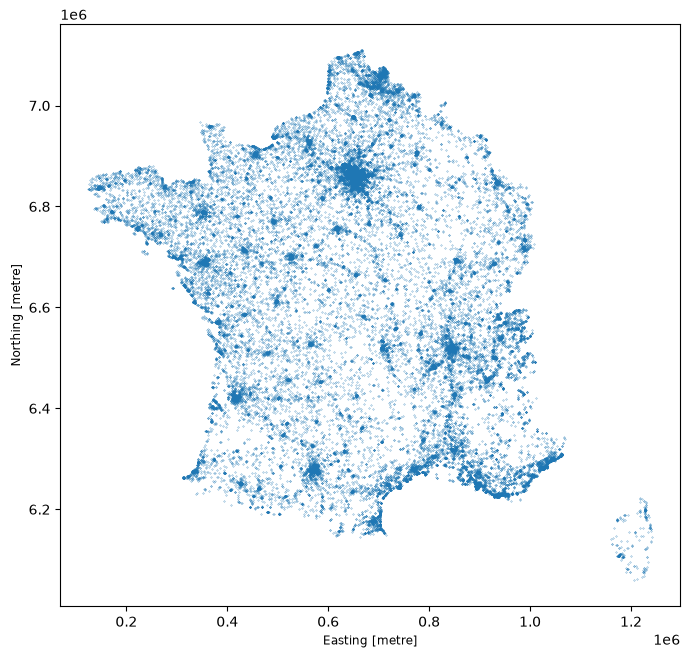

In [28]:
import geopandas as gpd

dvf_geo = gpd.GeoDataFrame(
    dvf,
    geometry=gpd.points_from_xy(dvf["longitude"], dvf["latitude"]),
    crs="EPSG:4326",
).to_crs("EPSG:2154")

print(dvf_geo.crs)
dvf_geo.sample(50_000, random_state=0).plot(markersize=0.05, figsize=(8, 8))

In [29]:
dvf_geo.to_parquet("/home/onyxia/work/dvf_ventes_2025.parquet")